# Vulkan GPU Ocean FFT Simulation (`oceanFFT` — No CUDA Required!)

A Vulkan GPU recreation of NVIDIA's classic **CUDA `oceanFFT`** demo (Jerry Tessendorf's *Simulating Ocean Water* Phillips-spectrum 2D Inverse FFT), built 100% on **`vknumpy` + `vkscipy` + `vkshader` (3D) + `vkcolorcet` + `vkpanel`**.

### How It Works on Vulkan GPU
1. Generates a 2D **Phillips ocean wave spectrum** $P(\mathbf{k})$ driven by wind speed & direction.
2. Evolves the complex wave amplitudes in time on GPU using the deep-water dispersion relation $\omega(k) = \sqrt{g k}$.
3. Computes the exact **256×256 2D Inverse FFT** (`65,536` ocean vertices) via separable Vulkan GPU GEMMs (`~25 ms/frame` on Steam Deck APU).
4. Computes **3D wave surface normals** via `vkscipy.ndimage.sobel` for sunlit Fresnel ocean shading + whitecap foam, AND renders an **interactive 3D ocean wave mesh** with `vkshader.interact_3d`!

In [1]:
import sys, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
from PIL import Image, ImageDraw
import vknumpy as vnp
import vkpandas as vpd
import vkscipy as vsp
import vkshader as vks
import vkcolorcet as cc
import vkpanel as pn

class VulkanOceanFFT:
    """Tessendorf Phillips-spectrum 2D IFFT ocean simulation running 100% on Vulkan GPU."""

    def __init__(self, N: int = 256, L: float = 200.0, wind_speed: float = 28.0, wind_dir_deg: float = 35.0, seed: int = 42):
        self.N = int(N)
        self.L = float(L)
        self.g = 9.81
        k_vals = (2.0 * np.pi / L) * np.fft.fftfreq(N, d=1.0 / N).astype(np.float32)
        kx, ky = np.meshgrid(k_vals, k_vals)
        k2 = kx * kx + ky * ky
        k = np.sqrt(k2)
        k_safe = np.where(k2 > 1e-8, k2, 1.0)
        L_p = (wind_speed ** 2) / self.g
        wx, wy = np.cos(np.radians(wind_dir_deg)), np.sin(np.radians(wind_dir_deg))
        k_dot_w = (kx * wx + ky * wy) / np.where(k > 1e-8, k, 1.0)
        A = 6e-4
        P_k = np.where(
            k2 > 1e-8,
            A * np.exp(-1.0 / (k_safe * L_p * L_p)) / (k_safe * k_safe) * (k_dot_w ** 2) * np.exp(-k2 * 0.05),
            0.0,
        )
        self.P_k = P_k.astype(np.float32)

        rng = np.random.default_rng(seed)
        h0_r = np.sqrt(0.5 * P_k).astype(np.float32) * rng.standard_normal((N, N)).astype(np.float32)
        h0_i = np.sqrt(0.5 * P_k).astype(np.float32) * rng.standard_normal((N, N)).astype(np.float32)
        h0n_r = np.roll(np.roll(h0_r[::-1, ::-1], 1, axis=0), 1, axis=1)
        h0n_i = np.roll(np.roll(h0_i[::-1, ::-1], 1, axis=0), 1, axis=1)

        # Precompute 1D unitary IFFT matrices on GPU
        idx = np.arange(N, dtype=np.float32)
        ang = (2.0 * np.pi / N) * np.outer(idx, idx)
        self.Wc = vnp.array(np.cos(ang).astype(np.float32) / np.sqrt(N))
        self.Ws = vnp.array(np.sin(ang).astype(np.float32) / np.sqrt(N))
        self.h0_r = vnp.array(h0_r)
        self.h0_i = vnp.array(h0_i)
        self.h0n_r = vnp.array(h0n_r)
        self.h0n_i = vnp.array(h0n_i)
        self.omega = vnp.array(np.sqrt(self.g * k).astype(np.float32))

    def height_field(self, t: float) -> vnp.ndarray:
        """Compute 2D ocean height field H(x, y, t) on Vulkan GPU."""
        c = vnp.cos(self.omega * float(t))
        s = vnp.sin(self.omega * float(t))
        hr = (self.h0_r * c - self.h0_i * s) + (self.h0n_r * c - self.h0n_i * s)
        hi = (self.h0_r * s + self.h0_i * c) + (-self.h0n_r * s - self.h0n_i * c)
        tr = self.Wc @ hr - self.Ws @ hi
        ti = self.Wc @ hi + self.Ws @ hr
        return tr @ self.Wc - ti @ self.Ws

ocean = VulkanOceanFFT(N=256, L=200.0, wind_speed=28.0, wind_dir_deg=35.0)
_ = ocean.height_field(0.0).to_numpy()  # warmup
t0 = time.perf_counter()
H0 = ocean.height_field(2.0)
print(f"256x256 Vulkan GPU Ocean 2D IFFT computed in {(time.perf_counter()-t0)*1000:.2f} ms")

256x256 Vulkan GPU Ocean 2D IFFT computed in 31.06 ms


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


## 1. Phillips Spectrum, Height Map & Sunlit Fresnel Ocean Surface

### What you're seeing:
- **Left — Phillips Wave Spectrum $\log(1 + P(\mathbf{k}))$**: frequency-domain energy of ocean waves aligned with the wind direction (`35°`).
- **Middle — GPU 2D IFFT Height Field (`vkcolorcet.kbc`)**: wave troughs (dark blue) to peaks (bright cyan-white).
- **Right — Sunlit Fresnel + Specular Ocean Surface**: computes per-pixel 3D surface normals via `vkscipy.ndimage.sobel(H)` on GPU, adding deep-water scattering, sky reflection, solar glints, and whitecap foam on steep crests!

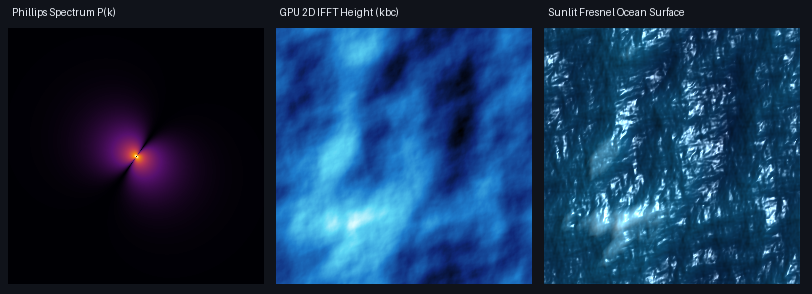

In [2]:
def render_lit_ocean(H_gpu: vnp.ndarray, sun_dir=(-0.55, 0.45, 0.70)) -> Image.Image:
    # Compute 3D surface normals on GPU via Sobel gradients
    gx = vsp.ndimage.sobel(H_gpu, axis=1).to_numpy() * 3.8
    gy = vsp.ndimage.sobel(H_gpu, axis=0).to_numpy() * 3.8
    h  = H_gpu.to_numpy()
    nx, ny, nz = -gx, -gy, np.ones_like(gx)
    inv_l = 1.0 / np.sqrt(nx * nx + ny * ny + nz * nz)
    nx *= inv_l; ny *= inv_l; nz *= inv_l

    L = np.array(sun_dir, dtype=np.float32); L /= np.linalg.norm(L)
    Hvec = L + np.array([0.0, 0.0, 1.0], dtype=np.float32); Hvec /= np.linalg.norm(Hvec)
    diff = np.clip(nx * L[0] + ny * L[1] + nz * L[2], 0.0, 1.0)
    spec = np.power(np.clip(nx * Hvec[0] + ny * Hvec[1] + nz * Hvec[2], 0.0, 1.0), 48.0)
    fresnel = np.power(1.0 - np.clip(nz, 0.0, 1.0), 3.0)
    foam = np.clip((h - np.percentile(h, 92)) / max(float(h.max() - np.percentile(h, 92)), 1e-4), 0.0, 1.0)

    deep = np.array([6.0, 32.0, 68.0])
    shallow = np.array([18.0, 105.0, 145.0])
    sky = np.array([150.0, 205.0, 240.0])
    h_norm = np.clip((h - h.min()) / max(float(h.max() - h.min()), 1e-5), 0.0, 1.0)[..., None]
    base = deep * (1.0 - h_norm) + shallow * h_norm
    rgb = base * (0.35 + 0.85 * diff[..., None]) + sky * (0.45 * fresnel[..., None]) + 255.0 * (0.85 * spec[..., None] + 0.55 * foam[..., None])
    return Image.fromarray(np.clip(rgb, 0, 255).astype(np.uint8), mode="RGB")

def _colorize(arr2d, cmap="kbc"):
    lo, hi = float(arr2d.min()), float(arr2d.max())
    norm = np.clip((arr2d - lo) / max(hi - lo, 1e-6), 0.0, 1.0)
    return Image.fromarray(cc.get_rgb_lut(cmap)[np.round(norm * 255.0).astype(np.int32)], mode="RGB")

spec_img = _colorize(np.log1p(np.fft.fftshift(ocean.P_k) * 5e4), cmap="inferno")
h_img    = _colorize(H0.to_numpy(), cmap="kbc")
lit_img  = render_lit_ocean(H0)

canvas = Image.new("RGB", (3 * 268 + 8, 294), (16, 19, 26))
draw = ImageDraw.Draw(canvas)
for i, (lbl, im) in enumerate([("Phillips Spectrum P(k)", spec_img), ("GPU 2D IFFT Height (kbc)", h_img), ("Sunlit Fresnel Ocean Surface", lit_img)]):
    x0 = 8 + i * 268
    draw.text((x0 + 4, 6), lbl, fill=(235, 240, 248))
    canvas.paste(im, (x0, 28))
canvas

## 2. Live Time-Stepping Ocean Wave Simulator (`vkpanel` + GPU 2D IFFT)

Drag the **Time (s)** slider to watch the Phillips-spectrum wave trains propagate live on your Vulkan GPU (~25 ms/frame)!

In [3]:
t_slider = pn.FloatSlider(name="Time (s)", start=0.0, end=20.0, step=0.25, value=2.0)
view_dd  = pn.Select(name="View", options=["Sunlit Fresnel Ocean", "3D Wireframe Wave Surface", "Height Map (kbc)"], value="3D Wireframe Wave Surface")

# Build NaN-separated 3D grid mesh indices (64x64 crisp wireframe lines) once
M = 64
step = ocean.N // M
gx_1d = np.linspace(-100.0, 100.0, M, dtype=np.float32)
XX, YY = np.meshgrid(gx_1d, gx_1d)

def _build_3d_mesh(H_np):
    Hs = H_np[::step, ::step]
    # Horizontal + vertical polylines separated by NaN
    nan_col = np.full((M, 1), np.nan, dtype=np.float32)
    xh = np.hstack([XX, nan_col]).ravel()
    yh = np.hstack([YY, nan_col]).ravel()
    zh = np.hstack([Hs, nan_col]).ravel()
    xv = np.hstack([XX.T, nan_col]).ravel()
    yv = np.hstack([YY.T, nan_col]).ravel()
    zv = np.hstack([Hs.T, nan_col]).ravel()
    z_all = np.concatenate([zh, zv])
    z_bin = np.clip(np.round((np.nan_to_num(z_all, nan=0.0) + 0.35) / 0.70 * 255.0), 0, 255).astype(np.int32)
    return vpd.DataFrame({
        "x": np.concatenate([xh, xv]),
        "y": np.concatenate([yh, yv]),
        "z": z_all,
        "h_col": z_bin,
    })

def _render_ocean_frame(t_val, view_mode):
    H_g = ocean.height_field(t_val)
    if view_mode == "Sunlit Fresnel Ocean":
        return render_lit_ocean(H_g).resize((520, 520))
    if view_mode == "Height Map (kbc)":
        return _colorize(H_g.to_numpy(), "kbc").resize((520, 520))
    mesh_df = _build_3d_mesh(H_g.to_numpy())
    return vks.render_3d(
        mesh_df, "x", "y", "z", width=700, height=460,
        x_range=(-100.0, 100.0), y_range=(-100.0, 100.0), z_range=(-0.4, 0.4),
        kind="lines", color_by="h_col", color_key=cc.kbc,
        basemap=None, yaw=0.65, pitch=0.42, dist=2.05, z_scale=0.35,
    )

pn.Card(
    pn.Row(t_slider, view_dd),
    pn.bind(_render_ocean_frame, t_slider, view_dd),
    title="Vulkan GPU Ocean FFT Simulator (256x256 2D IFFT)",
)

## 3. Live Auto-Animating 3D Ocean Surface Orbit (`VulkanOceanFFT` + `Interactive3DWidget`)

Automatically steps **Time $t$** forward on your Vulkan GPU so the ocean waves roll continuously **while you drag to orbit 360°, Shift/Right-drag to pan, and scroll to zoom**! Use the **Play/Pause** control or switch between **Deep Ocean (`kbc`)** and **Wave Height (`fire`)** live.

In [4]:
import ipywidgets as widgets
from IPython.display import display
from vkshader.viewer3d import Interactive3DWidget

anim_state = {
    "yaw": 0.55,
    "pitch": 0.42,
    "dist": 2.05,
    "pan_x": 0.0,
    "pan_y": 0.0,
    "t": 0.0,
    "mode": "Deep Ocean (kbc)",
    "z_scale": 0.35,
}

def _render_3d_ocean():
    t0 = time.perf_counter()
    H_np = ocean.height_field(anim_state["t"]).to_numpy()
    mesh = _build_3d_mesh(H_np)
    xr, yr = (-100.0, 100.0), (-100.0, 100.0)
    if anim_state["pan_x"] != 0.0 or anim_state["pan_y"] != 0.0:
        ox, oy = anim_state["pan_x"] * 100.0, anim_state["pan_y"] * 100.0
        xr = (xr[0] + ox, xr[1] + ox)
        yr = (yr[0] + oy, yr[1] + oy)
    col_by = "h_col" if anim_state["mode"] == "Deep Ocean (kbc)" else None
    col_key = cc.kbc if col_by else None
    img = vks.render_3d(
        mesh, "x", "y", "z", width=780, height=500,
        x_range=xr, y_range=yr, z_range=(-0.4, 0.4),
        kind="lines", color_by=col_by, color_key=col_key,
        basemap=None,
        yaw=anim_state["yaw"], pitch=anim_state["pitch"], dist=anim_state["dist"],
        z_scale=anim_state["z_scale"],
    )
    return img.to_jpeg(quality=84), (time.perf_counter() - t0) * 1000.0

jpg0, ms0 = _render_3d_ocean()
status_lbl = widgets.Label(value=f"t=0.00s | 3D Ocean IFFT + Render: {ms0:.1f} ms")

view_3d = None
def _refresh_3d():
    jpg, ms = _render_3d_ocean()
    view_3d.image_bytes = jpg
    status_lbl.value = f"t={anim_state['t']:.2f}s | 3D Ocean IFFT + Render: {ms:.1f} ms"

def _on_cam(yaw, pitch, dist, px, py):
    anim_state.update(yaw=yaw, pitch=pitch, dist=dist, pan_x=px, pan_y=py)
    _refresh_3d()

view_3d = Interactive3DWidget(
    width=780, height=500,
    camera=(anim_state["yaw"], anim_state["pitch"], anim_state["dist"], 0.0, 0.0),
    image_bytes=jpg0,
    on_camera_change=_on_cam,
)

# Auto-playing time-step widget (loops smoothly at ~12 FPS on GPU)
play = widgets.Play(value=0, min=0, max=1000, step=1, interval=90, repeat=True, playing=True)
t_bar = widgets.IntSlider(value=0, min=0, max=1000, description="Step:")
widgets.jslink((play, "value"), (t_bar, "value"))
play.observe(lambda ch: (anim_state.update(t=ch["new"] * 0.12), _refresh_3d()), names="value")

mode_dd = widgets.Dropdown(options=["Deep Ocean (kbc)", "Wave Height (Fire)"], value=anim_state["mode"], description="Color:")
mode_dd.observe(lambda ch: (anim_state.update(mode=ch["new"]), _refresh_3d()), names="value")

z_sl = widgets.FloatSlider(value=0.35, min=0.10, max=1.0, step=0.05, description="Wave Ht:")
z_sl.observe(lambda ch: (anim_state.update(z_scale=ch["new"]), _refresh_3d()), names="value")

display(widgets.VBox([widgets.HBox([play, t_bar, mode_dd, z_sl]), status_lbl, view_3d]))